In [2]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 11.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree

# Load the three datasets and replace dots in column names with underscores
hb = pd.read_csv("dataset/handball_wide.csv")
euro = pd.read_csv("dataset/EuroTraining.csv")
tennis = pd.read_csv("dataset/SlamsData.csv")
for df in (hb, euro, tennis):
    df.columns = df.columns.str.replace(".", "_", regex=False)
# columns are now: hb -> bet_probs_diff, euro -> unchanged, tennis -> age_30, player_1, ...

# Predictors and responses given on the sheet
X_hb = hb[["bet_probs_diff", "season"]];                                       y_hb = hb["scorediff"]
X_eu = euro[["GroupStage", "GDP", "MarketValue", "FifaRank", "UefaPoints", "CLPlayers"]]; y_eu = euro["Goals"]
X_t  = tennis[["rank", "points", "elo", "age_30"]];                            y_t  = tennis["win"]

# R's rpart defaults (minsplit = 20, minbucket = 7, cp = 0.01), approximated in sklearn.
# rpart's cp = minimum improvement as a fraction of the root node's error,
# which corresponds to min_impurity_decrease = cp * (impurity of the root).
def reg_tree(y, cp=0.01):
    return DecisionTreeRegressor(min_samples_split=20, min_samples_leaf=7,
                                 min_impurity_decrease=cp * np.var(y), random_state=1)

def clf_tree(y, cp=0.01):
    p = y.mean()
    return DecisionTreeClassifier(min_samples_split=20, min_samples_leaf=7,
                                  min_impurity_decrease=cp * 2 * p * (1 - p), random_state=1)

In [4]:
#Step 1: Fit the trees

# Regression trees for handball (scorediff) and Euro football (Goals)
tree_hb = reg_tree(y_hb).fit(X_hb, y_hb)
tree_eu = reg_tree(y_eu).fit(X_eu, y_eu)

# Classification tree for tennis (win)
tree_t = clf_tree(y_t).fit(X_t, y_t)

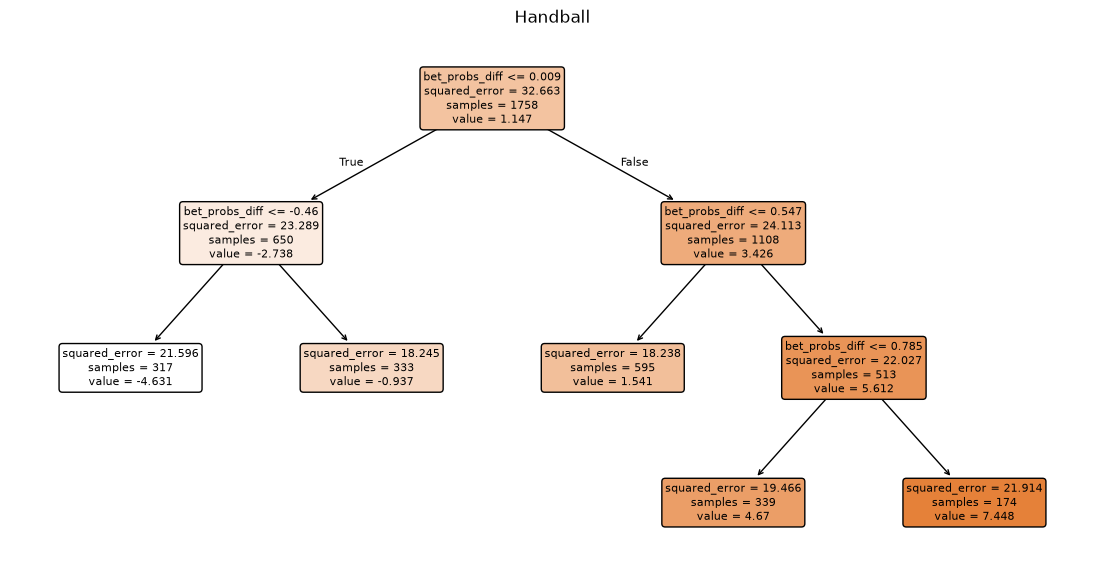

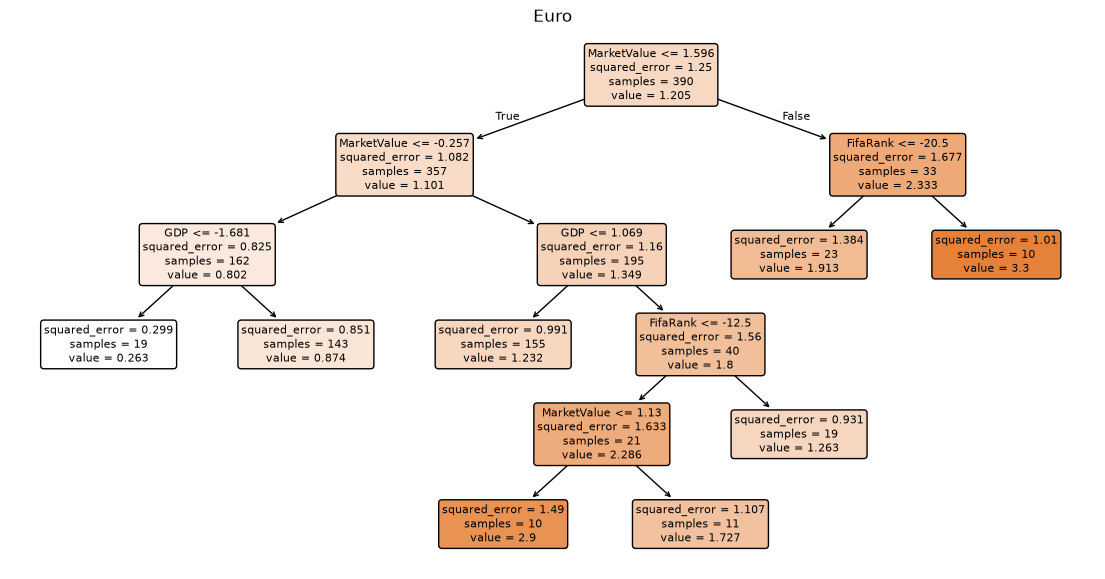

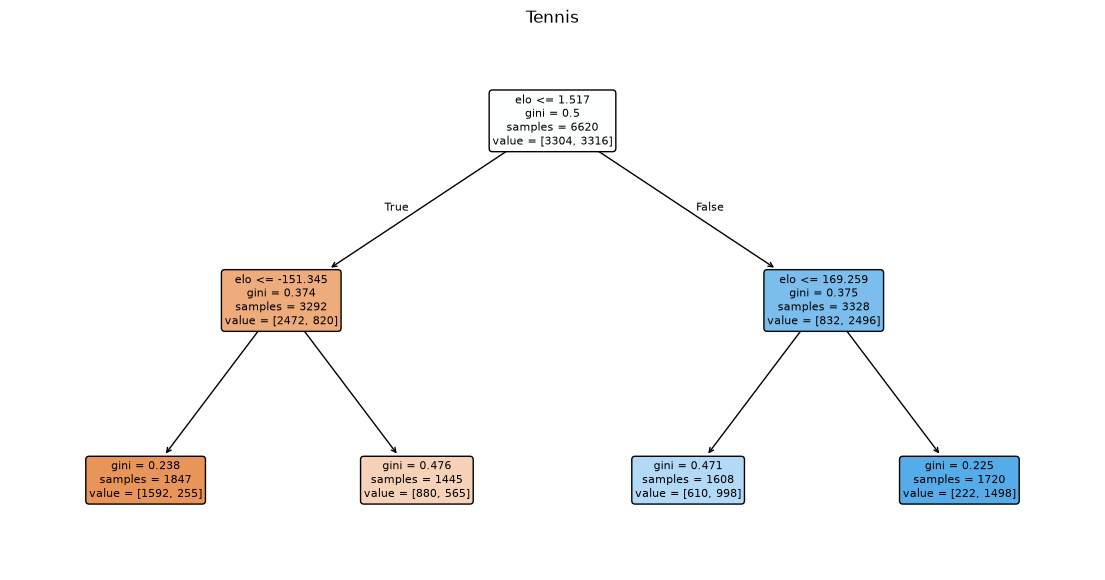

In [ ]:
#Step 2 Draw the trees

# One plot per tree (equivalent of rpart.plot)
for tree, X, title in [(tree_hb, X_hb, "Handball"), (tree_eu, X_eu, "Euro"), (tree_t, X_t, "Tennis")]:
    plt.figure(figsize=(14, 7))
    plot_tree(tree, feature_names=X.columns, filled=True, rounded=True, fontsize=8)
    plt.title(title)
    plt.show()

We fitted a regression tree for the handball data (scorediff, predictors bet_probs_diff and season), a regression tree for the Euro training data (Goals) and a classification tree for the tennis data (win). A CART splits the data into two child nodes by one predictor at a threshold, then repeats this in each node. The trees are therefore piecewise constant: the predictor space is divided into rectangular regions, and every match in a leaf gets the same prediction. For regression trees this is the mean of the response in the leaf, for the classification tree it is the proportion of won matches.
The handball tree has 5 leaves and only uses bet_probs_diff. The first split is at about 0.009, so it separates matches where the home team is favoured from those where it isn’t. season is not used at all. The Euro tree has 8 leaves, and the first split is on MarketValue at 1.596. The 33 matches above this threshold average 2.33 goals, against 1.10 for the other 357. GDP and FifaRank appear further down. The tennis tree has 4 leaves and only splits on elo, so it predicts four different winning probabilities: 0.138, 0.391, 0.621 and 0.871.



In [6]:
#Prediction

# Predicted goal difference (handball) and number of goals (Euro)
hb["pred"]    = tree_hb.predict(X_hb)
euro["pred"]  = tree_eu.predict(X_eu)

# Predicted winning probability (tennis): probability of class 1 (win)
tennis["prob"] = tree_t.predict_proba(X_t)[:, 1]

In [7]:
#MAE and RMSE (and accuracy for tennis)

def mae(y, pred):  return np.mean(np.abs(y - pred))
def rmse(y, pred): return np.sqrt(np.mean((y - pred) ** 2))

print("Handball | MAE:", mae(y_hb, hb["pred"]),   "| RMSE:", rmse(y_hb, hb["pred"]))
print("Euro     | MAE:", mae(y_eu, euro["pred"]), "| RMSE:", rmse(y_eu, euro["pred"]))

# Tennis: share of correctly predicted matches (predict a win if probability > 0.5)
print("Tennis   | correctly predicted:", ((tennis["prob"] > 0.5).astype(int) == y_t).mean())

Handball | MAE: 3.46383759587839 | RMSE: 4.4097101344319025
Euro     | MAE: 0.778885662794334 | RMSE: 0.971054543878097
Tennis   | correctly predicted: 0.7504531722054381


Step 3 and 4: Predictions and error measures


For handball we got MAE = 3.46 and RMSE = 4.41. For Euro we got MAE = 0.78 and RMSE = 0.97, and for tennis 75.0% of the matches were predicted correctly. RMSE is larger than MAE because it squares the errors, so large misses count more. For comparison, always predicting the overall mean would give an RMSE of about 5.72 in the handball data and 1.12 in the Euro data, so the trees do better than that. All these errors were computed on the training data, so they are probably somewhat too optimistic.



In [8]:
#Largest over- and underestimation

# Error = predicted - true: positive = overestimation, negative = underestimation
hb["error"]   = hb["pred"]   - y_hb
euro["error"] = euro["pred"] - y_eu

cols_hb = ["hometeam", "awayteam", "season", "bet_probs_diff", "scorediff", "pred", "error"]
cols_eu = ["Team", "Opponent", "Year", "GroupStage", "FifaRank", "MarketValue", "Goals", "pred", "error"]

print("Handball: largest overestimation");   print(hb.sort_values("error", ascending=False)[cols_hb].head(5))
print("Handball: largest underestimation");  print(hb.sort_values("error")[cols_hb].head(5))
print("Euro: largest overestimation");       print(euro.sort_values("error", ascending=False)[cols_eu].head(5))
print("Euro: largest underestimation");      print(euro.sort_values("error")[cols_eu].head(5))

# Tennis: matches with the most extreme predicted winning probabilities
cols_t = ["player_1", "player_2", "tournament", "win", "prob", "rank", "points", "elo", "age_30"]
print("Tennis: highest predicted win probability"); print(tennis.sort_values("prob", ascending=False)[cols_t].head(5))
print("Tennis: lowest predicted win probability");  print(tennis.sort_values("prob")[cols_t].head(5))

Handball: largest overestimation
             hometeam                awayteam  season  bet_probs_diff  \
1407  TBV Lemgo Lippe              GWD Minden    2021        0.570115   
1415  TBV Lemgo Lippe            SC Magdeburg    2021       -0.547495   
1457    TVB Stuttgart       Hannover-Burgdorf    2021        0.260164   
1010     MT Melsungen         HSC 2000 Coburg    2020        0.826360   
1449   TuS N-Lübbecke  SG Flensburg-Handewitt    2021       -0.704931   

      scorediff      pred      error  
1407        -12  4.669617  16.669617  
1415        -19 -4.630915  14.369085  
1457        -12  1.541176  13.541176  
1010         -5  7.448276  12.448276  
1449        -17 -4.630915  12.369085  
Handball: largest underestimation
                    hometeam           awayteam  season  bet_probs_diff  \
1310             HSG Wetzlar  Hannover-Burgdorf    2021        0.220076   
1725  SG Flensburg-Handewitt           THW Kiel    2022       -0.058331   
999              HSG Wetzlar       

Step 5: Largest over- and underestimation


In the handball data, the largest overestimation is match 1407 (Lemgo against Minden): the tree predicted a goal difference of +4.7, but Lemgo lost by 12. The largest underestimation is match 1310 (Wetzlar against Hannover), predicted +1.5 but ended +22. Since the tree only uses the betting information, it cannot predict upsets or very one-sided matches. Inside a leaf the actual goal differences vary a lot (the squared error is still about 18 to 22 in the leaves, so the standard deviation is around 4 to 5 goals). Four of the five largest overestimations are from season 2021, which may be chance, but we did not test it.



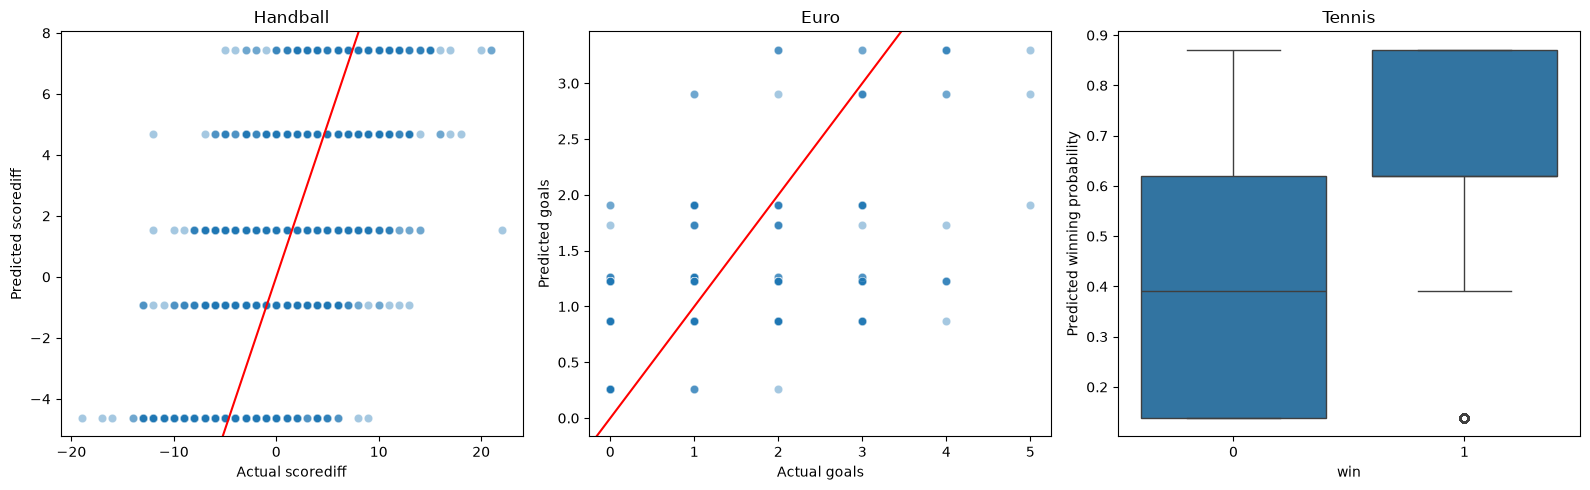

In [11]:
#Plots

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

# Handball: predicted vs. actual goal difference, bisecting line = perfect prediction
sns.scatterplot(x=y_hb, y=hb["pred"], alpha=0.4, ax=ax[0])
ax[0].axline((0, 0), slope=1, color="red")
ax[0].set(title="Handball", xlabel="Actual scorediff", ylabel="Predicted scorediff")

# Euro: predicted vs. actual number of goals
sns.scatterplot(x=y_eu, y=euro["pred"], alpha=0.4, ax=ax[1])
ax[1].axline((0, 0), slope=1, color="red")
ax[1].set(title="Euro", xlabel="Actual goals", ylabel="Predicted goals")

# Tennis: boxplots of the predicted winning probability for won (1) and lost (0) matches
sns.boxplot(x=y_t, y=tennis["prob"], ax=ax[2])
ax[2].set(title="Tennis", xlabel="win", ylabel="Predicted winning probability")

plt.tight_layout(); plt.show()

In the handball scatter plot the predictions lie on 5 horizontal lines, one per leaf, and they are spread much less than the actual values (from about -5 to +8, against -19 to +22). The tree pulls extreme matches toward the middle. The Euro plot looks similar, with only 8 different predictions. In the tennis boxplots, won matches receive higher predicted probabilities than lost matches, so the tree separates the two groups, but the boxplots overlap a lot, which fits an accuracy of 75%

Different predicted probabilities: 4
Leaves: 4
prob
0.138    1847
0.871    1720
0.621    1608
0.391    1445
Name: count, dtype: int64
Different predicted probabilities (cp = 0.001): 14
Correctly predicted (cp = 0.01):  0.7504531722054381
Correctly predicted (cp = 0.001): 0.7522658610271903


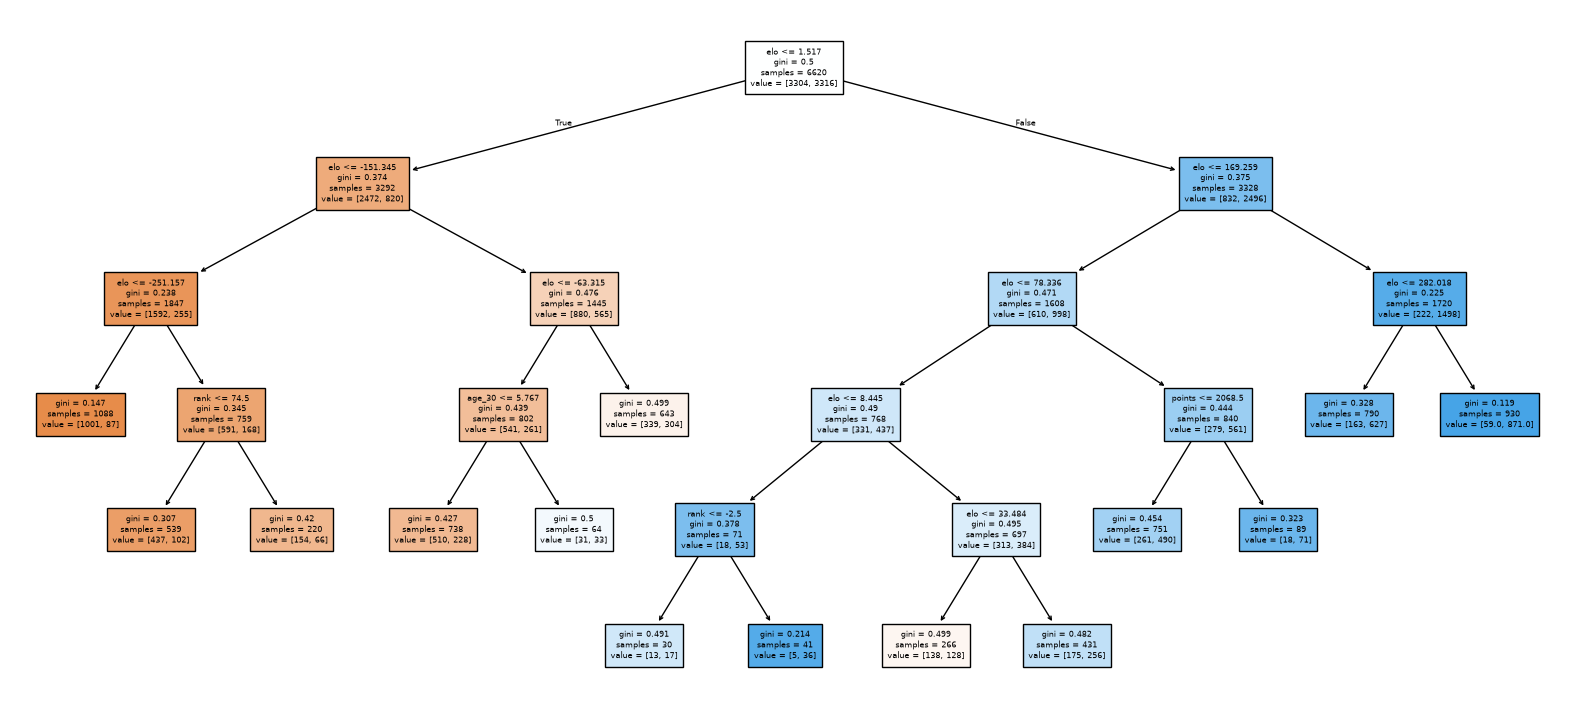

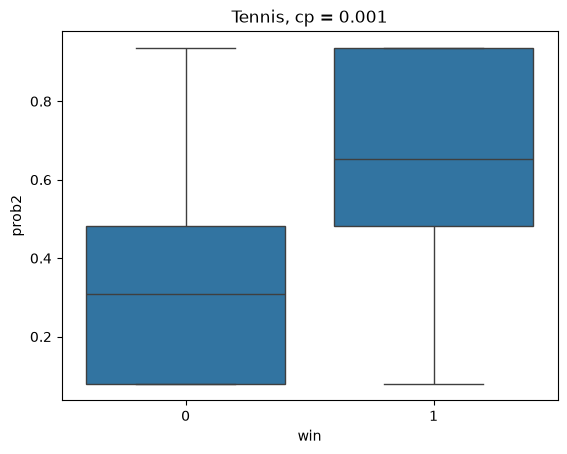

In [10]:
#Closer look at the tennis tree

# How many different winning probabilities does the tree predict? (= number of distinct leaves)
print("Different predicted probabilities:", tennis["prob"].nunique())
print("Leaves:", tree_t.get_n_leaves())
print(tennis["prob"].round(3).value_counts())

# Refit with cp = 0.001 (the tree is allowed to grow much further)
tree_t2 = clf_tree(y_t, cp=0.001).fit(X_t, y_t)
tennis["prob2"] = tree_t2.predict_proba(X_t)[:, 1]

print("Different predicted probabilities (cp = 0.001):", tennis["prob2"].nunique())
print("Correctly predicted (cp = 0.01): ", ((tennis["prob"]  > 0.5).astype(int) == y_t).mean())
print("Correctly predicted (cp = 0.001):", ((tennis["prob2"] > 0.5).astype(int) == y_t).mean())

# Plot the new tree and the new boxplots
plt.figure(figsize=(20, 9))
plot_tree(tree_t2, feature_names=X_t.columns, filled=True, fontsize=6)
plt.show()

sns.boxplot(x=y_t, y=tennis["prob2"])
plt.title("Tennis, cp = 0.001"); plt.show()

Step 7: The tennis tree

The tree predicts 4 different winning probabilities, one per leaf. Because there are only four values, the boxes of the boxplots lie on these values. For lost matches the quartiles are 0.138, 0.391 and 0.621. For won matches more than half of the matches have 0.621 or 0.871, so the box is pushed to the top and the low values appear as outliers.
The tree stops early because of the complexity parameter cp. As discussed in the lecture, a split is only made if it improves the fit by a minimum amount, here cp times the error of the root node. After the first splits on elo, further splits improve the fit by less than this, so the tree stops at 4 leaves. With cp = 0.001 the tree grows to 14 leaves and also uses rank, points and age_30, and it predicts 14 different probabilities. The share of correct predictions only increases from 75.05% to 75.23%. This small gain is measured on the training data. A tree with higher capacity always fits the training data better, but it may overfit, so we cannot say from this that the larger tree is better. elo seems to contain almost all of the useful information.




# Study Notes: Trees (CART)

## What we did in one paragraph

We fitted three trees. A regression tree predicts a number: the goal difference in handball and the number of goals in the Euro data. A classification tree predicts a class: whether player 1 wins a tennis match. For each tree we looked at what it uses, how big its errors are, which matches it gets most wrong, and (for tennis) what happens when the tree is allowed to grow bigger.

---

## How a tree works

### The basic idea

A tree asks yes/no questions about the predictors, like "is `bet_probs_diff` smaller than 0.009?". Each answer sends a match to the left or to the right. After a few questions the match ends up in a leaf, and the leaf gives the prediction.

- Regression tree: the prediction is the average of the response of all training matches in that leaf.
- Classification tree: the prediction is the share of each class in that leaf. For tennis, the share of won matches is the predicted winning probability.

Because every match in a leaf gets the same prediction, a tree with 5 leaves can only predict 5 different values. This explains many of the plots later.

### How the tree chooses a question

The tree tries every predictor and every possible threshold, and takes the split that makes the two resulting groups as "pure" as possible.

- Regression: purity means a small variance (squared error) of the response inside each group. The best constant for a group is its mean.
- Classification: purity is measured with the Gini impurity (equivalent to minimizing the Brier score). A group is pure if almost all its matches belong to one class.

It does this one node at a time and never looks ahead. This is what "greedy" means. Thresholds are placed in the middle between two observations, which makes the tree more likely to work well on new data.

### When does the tree stop?

If we let it, the tree would keep splitting until every leaf has one match. That would take long and overfit. So we use stopping rules, for example a minimum number of matches in a node, or a minimum improvement for a split to be allowed. The minimum improvement is controlled by the complexity parameter `cp`: a split must improve the fit by at least `cp` times the error of the root node. A bigger `cp` gives a smaller tree, a smaller `cp` gives a bigger tree.

(Pruning is the other way: grow a big tree first, then cut branches back so that the cross-validated error is best. We did not do that here.)

### Why trees are popular

- They find non-linear effects and interactions by themselves.
- They ignore useless predictors automatically.
- They need no assumptions about the distribution of the data.
- You can read them like a flow chart.

The downside is that they predict only a few different values and can change a lot if the data change a little.

## What our three trees show

### Handball (predicting `scorediff`)

- The tree has 5 leaves and uses only `bet_probs_diff`. `season` is never used.
- The first question is whether `bet_probs_diff` is above or below about 0.009, so basically whether the home team is the favourite or not.
- The predictions go from about -4.6 (home team is a big underdog) to about +7.4 (home team is a big favourite).
- Why is `season` missing? No split on `season` improves the squared error enough, compared with splits on the betting variable. This agrees with the linear regression, where `season` was not significant.

### Euro football (predicting `Goals`)

- The tree has 8 leaves. The first split is on `MarketValue` at about 1.6.
- The 33 observations with a very high market value score 2.33 goals on average, the other 357 only 1.10.
- `GDP` and `FifaRank` appear lower in the tree. `GroupStage`, `UefaPoints` and `CLPlayers` are not used.
- The big message: team market value is the main driver of goals.

### Tennis (predicting `win`)

- The tree has 4 leaves and uses only `elo`.
- The 4 leaves have these winning probabilities, from the lowest to the highest `elo`: 0.138, 0.391, 0.621, 0.871.
- Where do these numbers come from? The share of won matches in each leaf. For example, in the leaf with the highest `elo`, 1498 of 1720 matches were won, and 1498 / 1720 = 0.871.
- A match with probability above 0.5 is predicted as a win, otherwise as a loss. With this rule 75.0% of the matches are predicted correctly. Guessing would give 50%, because the data are balanced.

---

## How good are the predictions?

| Data set | MAE | RMSE | RMSE if we always predict the mean |
|---|---|---|---|
| Handball | 3.46 | 4.41 | 5.72 |
| Euro | 0.78 | 0.97 | 1.12 |
| Tennis | 75.0% correct | | |

- **MAE** is the average size of the error (in goals). A handball MAE of 3.46 means the prediction is off by about 3.5 goals on average.
- **RMSE** squares the errors first, so big mistakes count more. This is why it is always at least as large as the MAE.
- The last column is the RMSE of the most boring prediction: always the overall mean. It is simply the square root of the root node's squared error. Because the trees are better than that, they have learned something useful. For Euro the improvement is small (1.12 to 0.97), which shows how random football goals are.
- **Important:** all these errors are computed on the data the trees were fitted on. They are therefore a bit too optimistic.

## Which matches does the tree get wrong, and why?

### Handball examples

- Overestimated: Lemgo against Minden (2021). The tree predicted +4.7, but Lemgo lost by 12.
- Underestimated: Wetzlar against Hannover. The tree predicted +1.5, but the match ended +22.

Why can this happen?
- The tree only knows the betting information, and there are only 5 possible predictions.
- Inside one leaf the real goal differences are very spread out. The squared error in the leaves is still about 18 to 22, so the typical deviation is about 4 to 5 goals. Upsets and blowouts are not predictable from the bookmaker's probabilities alone.
- Four of the five biggest overestimations are from season 2021. This might be chance, and we did not test it, so only mention it as an observation.

(For Euro and tennis, look at your own output: for Euro, whether the biggest errors are high-scoring games that the tree cannot reach; for tennis, whether the extreme predicted probabilities were upsets.)

---

## The plots in plain words

- **Handball and Euro scatter plots (predicted against actual):** the points sit on a few horizontal lines, one per leaf. If the model were perfect, they would lie on the diagonal. The predictions are packed into a small range, while the actual values spread out much wider. The tree gets the direction right but pulls everything toward the middle.
- **Tennis boxplots:** won matches have higher predicted probabilities than lost matches, which is good. But the two boxplots overlap a lot, which matches the 75% accuracy.

---

## The tennis tree in detail (Step 7)

### Why do the two boxplots look so different?

The tree only has four possible values, so the boxes land exactly on those values. Look at how the matches are spread over the four leaves:

| Leaf (probability) | Lost matches | Won matches |
|---|---|---|
| 0.138 | 1592 | 255 |
| 0.391 | 880 | 565 |
| 0.621 | 610 | 998 |
| 0.871 | 222 | 1498 |

- Lost matches: almost half of them are in the lowest leaf, so the box runs from 0.138 up to 0.621 with the median at 0.391.
- Won matches: more than half are in the top two leaves, so the box is squeezed between 0.621 and 0.871. The few won matches in the lowest leaf show up as outliers.

### Why does the tree stop so early?

The first splits on `elo` improve the fit clearly. After that, any further split improves the fit by less than `cp` times the root error, so with the default `cp = 0.01` the tree stops at 4 leaves. Often a split would produce two groups that both still predict "lost" (or both "won"), so the number of correct predictions would not change.

(To be safe: if someone asks for the exact definition of cp for classification, say what the documentation says and do not guess. You can check `?rpart.control`.)

### What changes with cp = 0.001?

- The tree grows from 4 to 14 leaves and now also uses `rank`, `points` and `age_30`.
- It predicts 14 different probabilities instead of 4.
- Accuracy only goes from 75.05% to 75.23%, which is about 12 more correct matches out of 6620.
- The reading: `elo` already carries almost all of the useful information, and the extra splits mostly add detail without changing many predictions.

---

## Overfitting and capacity (the main theory point)

- **Capacity** means how flexible a model is. A tree with many leaves has high capacity, a tree with a few leaves has low capacity.
- **Underfitting:** the model is too simple, so even the training error is high.
- **Overfitting:** the model is so flexible that it learns noise. The training error is very low, but the error on new data is much higher. A large gap between training and test error is the sign.
- When capacity goes up, the training error always goes down. The test error first goes down and then goes up again. The best model sits in between.
- The lecture examples all show this. For example, the tree with `minsplit` 60 / 12 / 2 had test errors of 0.40 / 0.32 / 0.35, so the middle setting was best.
- That is why the small gain from `cp = 0.001` is not proof of a better model. It is measured on the same data the tree was trained on. To decide properly, we would need test data or cross-validation, and the tuning parameter (here `cp`) would be chosen with it.

---

## Things to remember

1. A tree gives one constant per leaf: the mean (regression) or the class share (classification).
2. Splits are chosen greedily by minimizing squared error (regression) or Gini impurity (classification).
3. `cp` controls how big the tree grows: bigger `cp`, smaller tree.
4. Few leaves means few distinct predictions, which is why the plots look like steps.
5. Our trees beat the "predict the mean" baseline, but the errors are still large because match results are noisy.
6. All errors here are training errors, so they are optimistic, and a bigger tree is not automatically a better tree.
7. The trees were built in Python (scikit-learn) with settings similar to `rpart`, so the exact splits can differ slightly from R.